Seeding for reproducibility

In [ ]:
import random
random.seed(0)

import numpy as np
np.random.seed(0)

import tensorflow as tf
tf.random.set_seed(0)

OS library is used to interact with os, create files, folders, directories etc

zipfiles to unzip files

PIL for image proecessing like resizing

keras - high level api by tensorflow for building cnn

Tensorflow - open source ml

In [ ]:
import os
from zipfile import ZipFile
from PIL import Image

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models

**Data Curation**


In [ ]:
!pip install -q -U kaggle     #kaggle already exists but -u is used to update it here

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 10.0 MB/s eta 0:00:00


This is API authentication and this token(plant disease) is used to communicate with Kaggle

In [ ]:
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("Plant")

In [ ]:
!kaggle datasets download -d abdallahalidev/plantvillage-dataset

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [02:00<00:00, 18.2MB/s]



In [ ]:
!ls

plantvillage-dataset.zip  sample_data


To unzip the dataset

In [ ]:
with ZipFile("plantvillage-dataset.zip", 'r') as zip_ref:
    zip_ref.extractall()

In [ ]:
print(os.listdir("plantvillage dataset"))    #to list the directories in the unzipped dataset


print(len(os.listdir("plantvillage dataset/segmented")))     #lists the number
print(os.listdir("plantvillage dataset/segmented")[:5])      #lists the names inside this folder

print(len(os.listdir("plantvillage dataset/color")))
print(os.listdir("plantvillage dataset/color")[:5])

print(len(os.listdir("plantvillage dataset/grayscale")))
print(os.listdir("plantvillage dataset/grayscale")[:5])

['segmented', 'grayscale', 'color']
38
['Potato___Late_blight', 'Raspberry___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Grape___healthy', 'Apple___Apple_scab']
38
['Potato___Late_blight', 'Raspberry___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Grape___healthy', 'Apple___Apple_scab']
38
['Potato___Late_blight', 'Raspberry___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Grape___healthy', 'Apple___Apple_scab']


Colour subfolder has 38 sub folders which futher contain plant name and disease names

In [ ]:
print(len(os.listdir("plantvillage dataset/color/Grape___healthy")))
print(os.listdir("plantvillage dataset/color/Grape___healthy")[:5])

423
['bfd1909d-6235-41a4-a24a-eeea9ffdd0a5___Mt.N.V_HL 9042.JPG', '0ec29818-c70e-4586-9481-3201a67b7910___Mt.N.V_HL 6175.JPG', '6b11a8e2-a729-4f80-9836-e90402c0b47f___Mt.N.V_HL 6062.JPG', 'bfeeb99b-946a-4edb-b59e-445d682d891d___Mt.N.V_HL 6061.JPG', '18db578d-ab6c-4469-8e07-01d8c211a91f___Mt.N.V_HL 8983.JPG']


**Data Preprocessing**

We are going with colour subfolder for our model. Hence we are creating a base directory with that dataset path

In [ ]:
base_dir = 'plantvillage dataset/color'

In [ ]:
# Image Parameters
img_size = 224    #resizes the images to this dimension
batch_size = 32    #number of images used to training at once

**Train Test Split**

Keras splits into 2 subsets only - hence we are dividing this subset into training subset and validation subset

Imagedatagenerator - a keras utility for building and loading images in batches and augmenting them for preprocessing

In [ ]:
# Image Data Generators
data_gen = ImageDataGenerator(
    rescale=1./255,   #normalisation- used to get pixel values between 0 and 1 i.e a gaussian distribution
    validation_split=0.2  # Use 20% of data for validation and 80% for testing
)

flowfromdirectory looks into the dataset and assigns class from the folder names and groups images into batches - useful for multiclass classification

In [ ]:
# Train Generator
train_generator = data_gen.flow_from_directory(
    base_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    subset='training',
    class_mode='categorical'      #for one hot encoding
)

Found 43456 images belonging to 38 classes.


In [ ]:
# Validation Generator
validation_generator = data_gen.flow_from_directory(
    base_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    subset='validation',
    class_mode='categorical'
)

Found 10849 images belonging to 38 classes.


**Convolutional Neural Network**

In [ ]:
# Model Definition
model = models.Sequential()   #sequential is a class in the models module of keras. it is used to build cnn in a sequential manner(layer after layer)

model.add(layers.Input(shape=(img_size,img_size,3)))       #p
model.add(layers.Conv2D(32, (3, 3), activation='relu'))    #performs convolution. used 32 filters/kernels which slides over the image producing a feature map
#shape is a function which returns the size #relu is a function which makes all -ve values 0 and positive values linear
model.add(layers.MaxPooling2D(2, 2))    #.add is a method used to specify what the next layer is in the sequence
#max pooling layer uses (2,2) block on the feature map and in this block we take max value. stride for max pooling is taken as 2 so it moves 2 steps ahead which reduces the size of feature map
#and reduces computation

model.add(layers.Conv2D(64, (3, 3), activation='relu'))     #convolution but with 64 layers
model.add(layers.MaxPooling2D(2, 2))

model.add(layers.Flatten())     #we are flattening the feature map to a 1D vector for the dense layer to process it
model.add(layers.Dense(256, activation='relu'))    #dense layer which is fully connected neuron layer with 256 neurons? why 256? conventional sizing used usually. using 512 makes it harder during
#computation
model.add(layers.Dense(train_generator.num_classes, activation='softmax'))  #output layer where train gen which gives 38 classes and we are not hardcoding this 38. 38 number of outputs are possible
#using softmax activation because its multi class

In [ ]:
# model summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    47,776,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,805,158 (182.36 MB)

 Trainable params: 47,805,158 (182.36 MB)

 Non-trainable params: 0 (0.00 B)

Optimiser used in Adam which is a combination of momentum approach and effective learning rate.

Loss function used is categorical cross entropy

metrics on which performance of mdoel is judged is accuracy i.e what percentage of images does it correctly classify

In [ ]:
# Compile the Model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

**Model training**

history is the variable that contains the entire training process of the model. it contains the loss values, accuracy values in each step of the epoch.

train_gen is the training dataset

validation_gen is the test dataset

An epoch tell us how many times we want to train the model over the complete dataset

In [ ]:
# Training the Model
history = model.fit(
    train_generator,
    epochs=5,  # Number of epochs
    validation_data=validation_generator
)

Epoch 1/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 152s 106ms/step - accuracy: 0.7440 - loss: 0.9071 - val_accuracy: 0.8596 - val_loss: 0.4557
Epoch 2/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 132s 97ms/step - accuracy: 0.9177 - loss: 0.2571 - val_accuracy: 0.8691 - val_loss: 0.4258
Epoch 3/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 128s 94ms/step - accuracy: 0.9643 - loss: 0.1104 - val_accuracy: 0.8552 - val_loss: 0.5341
Epoch 4/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 145s 107ms/step - accuracy: 0.9727 - loss: 0.0834 - val_accuracy: 0.8471 - val_loss: 0.6483
Epoch 5/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 139s 102ms/step - accuracy: 0.9798 - loss: 0.0643 - val_accuracy: 0.8780 - val_loss: 0.5740


**Model Evaluation**

In [ ]:
# Model Evaluation
print("Evaluating model...")
val_loss, val_accuracy = model.evaluate(validation_generator, steps=validation_generator.samples // batch_size)
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

Evaluating model...
339/339 ━━━━━━━━━━━━━━━━━━━━ 27s 81ms/step - accuracy: 0.8780 - loss: 0.5731
Validation Accuracy: 87.80%


This is to display the loss curve and accuracy curve

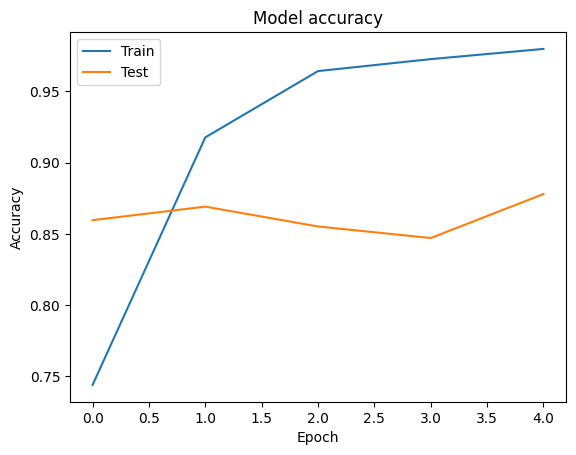

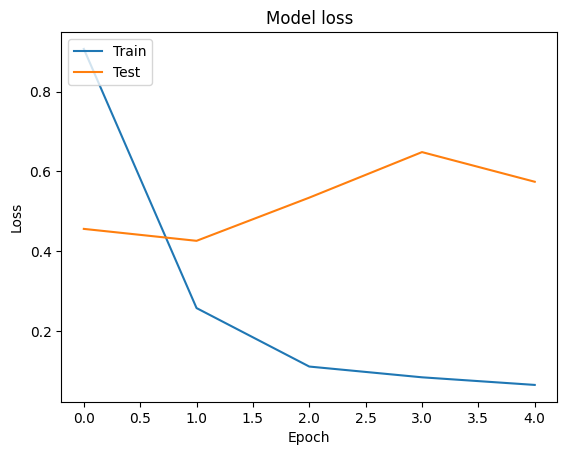

In [ ]:
# Plot training & validation accuracy values
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

**Building a Predictive System**

In [ ]:
# Function to Load and Preprocess the Image using Pillow
def load_and_preprocess_image(image_path, target_size=(224, 224)):
    # Load the image
    img = Image.open(image_path)
    # Resize the image
    img = img.resize(target_size)
    # Convert the image to a numpy array
    img_array = np.array(img)
    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)
    # Scale the image values to [0, 1]
    img_array = img_array.astype('float32') / 255.
    return img_array

# Function to Predict the Class of an Image
def predict_image_class(model, image_path, class_indices):
    preprocessed_img = load_and_preprocess_image(image_path)
    predictions = model.predict(preprocessed_img)
    predicted_class_index = np.argmax(predictions, axis=1)[0]
    predicted_class_name = class_indices[predicted_class_index]
    return predicted_class_name